# Part 2: Whole-slide inference (CAMELYON16)

**Goal:** run the Part 1 model over entire lymph-node slides, which are about 100,000 × 200,000 pixels each, and answer two questions:
1. **Where** is the tumour? (a heatmap)
2. **Is there** a metastasis on this slide? (one score per slide, evaluated with ROC AUC)

**Why it matters for AIRA Matrix:** their images are ~50K × 50K. This notebook is the "how do you handle a gigapixel image" answer: never load the whole slide; skip the glass; read big blocks; cut windows in memory; run the GPU in fp16.

**Needs:** `best.pt` from Part 1 on Drive.

| Section | What happens |
|---|---|
| 1 | Setup and settings |
| 2 | Labels, annotations, slide list |
| 3 | Open one slide: the pyramid |
| 4 | Tissue mask (skip the glass) |
| 5 | The grid: cells, windows, blocks |
| 6 | Run the model over one slide |
| 7 | All slides: download → heatmap → delete |
| 8 | Slide-level results |
| 9 | Lesion-level results (with annotations) |
| 10 | Summary |

## 1. Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q openslide-python openslide-bin awscli

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import glob
import json
import math
import shutil
import subprocess
import time
import xml.etree.ElementTree as ET
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import openslide
from PIL import Image
from scipy import ndimage as ndi
from skimage import morphology
from skimage.color import rgb2hsv
from skimage.draw import polygon as draw_polygon
from skimage.filters import threshold_otsu
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import Dataset, DataLoader

In [4]:
DATA = '/content/data'
OUT = '/content/drive/MyDrive/patho'
CAM = f'{DATA}/camelyon16'                       # reference.csv + annotations
SLIDE_TMP = '/content/slide_tmp'                 # one slide at a time lives here
MODEL_PATH = f'{OUT}/runs/pcam_resnet18/best.pt'
HEATMAPS = f'{OUT}/heatmaps'
EVAL = f'{OUT}/results/camelyon_eval'
BUCKET = 's3://camelyon-dataset/CAMELYON16'

N_TUMOUR, N_NORMAL = 20, 20      # test slides to use (all test slides: 49 / 80)

DOWNSAMPLE = 4.0       # read at pyramid level 2 (~10x), exactly how PCam was cut
TILE = 96              # model input
STRIDE = 32            # = one heatmap cell. the PCam label describes the centre 32 x 32
CELLS_PER_BLOCK = 32   # 32 x 32 cells read from the slide in one go
THUMB_DS = 32          # thumbnail for the tissue mask (1/32 of full size)
MIN_TISSUE = 0.1       # score a cell if at least 10% of it is tissue
BLOCKS_PER_BATCH = 2
CHUNK = 1024           # windows per forward pass
WORKERS = 2
CELL_THRESHOLD = 0.5   # cell counts as tumour above this
SEED = 0

In [5]:
for d in [CAM, SLIDE_TMP, HEATMAPS, EVAL]:
    os.makedirs(d, exist_ok = True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'

# the part 1 model
def build_model(arch = 'resnet18'):
    m = getattr(torchvision.models, arch)(weights = None)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m

ckpt = torch.load(MODEL_PATH, map_location = device, weights_only = False)
model = build_model(ckpt['config']['arch'])
model.load_state_dict(ckpt['state_dict'])
model = model.to(device).eval().to(memory_format = torch.channels_last)
MEAN = torch.tensor([0.485, 0.456, 0.406], device = device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device = device).view(1, 3, 1, 1) * 255
print('model from epoch', ckpt['epoch'], 'on', device)

model from epoch 5 on cuda


## 2. Labels, annotations and the slide list

The CAMELYON16 data is on a public AWS bucket, so no account is needed (`--no-sign-request`).
- `reference.csv`: for every slide, `type` (tumor / normal), `class` (macro / micro metastasis, or negative), `center` (which of the 2 hospitals)
- `annotations/test_XXX.xml`: the tumour outlines drawn by pathologists (only for tumour slides)

In [6]:
!aws s3 cp --no-sign-request --only-show-errors {BUCKET}/evaluation/reference.csv {CAM}/
!aws s3 sync --no-sign-request --only-show-errors {BUCKET}/annotations/ {CAM}/annotations/ --exclude "*" --include "test_*"
!ls {CAM}/annotations | wc -l

49


**Only TEST slides.** PCam's training patches were cut from the CAMELYON16 *training* slides (`tumor_xxx`, `normal_xxx`). Testing on those would test the model on slides it has seen. So we only use `test_xxx` slides, and the code below refuses anything else.

In [7]:
ref = pd.read_csv(f'{CAM}/reference.csv')
ref['slide'] = ref['image'].str.replace('.tif', '', regex = False)
ref = ref.set_index('slide')
test = ref[ref.index.str.startswith('test_')]
print(test.groupby(['type', 'class']).size())

pick = pd.concat([test[test.type == 'tumor'].sample(N_TUMOUR, random_state = SEED),
                  test[test.type == 'normal'].sample(N_NORMAL, random_state = SEED)]).sort_index()
slides = pick.index.tolist()
print(len(slides), 'slides:', slides[:6], '...')

type    class   
normal  negative    80
tumor   macro       22
        micro       27
dtype: int64
40 slides: ['test_004', 'test_006', 'test_007', 'test_010', 'test_015', 'test_016'] ...


## 3. Open one slide: the pyramid

A slide file stores the same image at several sizes (**levels**). Level 0 is full resolution (40×, ~0.24 µm per pixel); each next level is 2× smaller. The file is only 1-2 GB because it is JPEG-compressed in 256 px tiles. **OpenSlide** decodes only the tiles a request touches.

Our `read()` function always takes the position in **level-0 pixels** (OpenSlide's rule), picks the right level, and paints anything outside the slide white like glass.

In [8]:
def download_slide(name):
    path = f'{SLIDE_TMP}/{name}.tif'
    if not os.path.exists(path):
        subprocess.run(['aws', 's3', 'cp', '--no-sign-request', '--only-show-errors',
                        f'{BUCKET}/images/{name}.tif', path], check = True)
    return path


class SlideReader:
    def __init__(self, path):
        self.slide = openslide.OpenSlide(path)
        self.width, self.height = self.slide.dimensions
        self.downsamples = [float(d) for d in self.slide.level_downsamples]
        self.mpp0 = float(self.slide.properties.get('openslide.mpp-x', 0.243))   # microns per pixel at level 0

    def read(self, x0, y0, w, h, ds):
        """(h, w, 3) RGB at downsample ds. x0, y0 in level-0 pixels, may be outside the slide."""
        level = max(i for i, d in enumerate(self.downsamples) if d <= ds * 1.001)   # coarsest level that is fine enough
        lds = self.downsamples[level]
        lw, lh = math.ceil(w * ds / lds), math.ceil(h * ds / lds)
        lx, ly = math.floor(x0 / lds), math.floor(y0 / lds)
        W, H = self.slide.level_dimensions[level]
        cx0, cy0, cx1, cy1 = max(lx, 0), max(ly, 0), min(lx + lw, W), min(ly + lh, H)   # clip to the slide
        canvas = np.full((lh, lw, 3), 255, np.uint8)
        if cx1 > cx0 and cy1 > cy0:
            rgba = np.asarray(self.slide.read_region((int(cx0 * lds), int(cy0 * lds)), level, (cx1 - cx0, cy1 - cy0)))
            rgb = rgba[..., :3].copy()
            rgb[rgba[..., 3] == 0] = 255                       # transparent = outside the scan = white
            canvas[cy0 - ly:cy0 - ly + rgb.shape[0], cx0 - lx:cx0 - lx + rgb.shape[1]] = rgb
        if (lw, lh) != (w, h):
            canvas = np.asarray(Image.fromarray(canvas).resize((w, h), Image.BILINEAR))
        return canvas

    def thumbnail(self, ds):
        return self.read(0, 0, round(self.width / ds), round(self.height / ds), ds)

test_004 98,304 x 103,936 px, 0.227 um/px at level 0
levels (downsample): [1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0]
as raw RGB this would need 31 GB of RAM


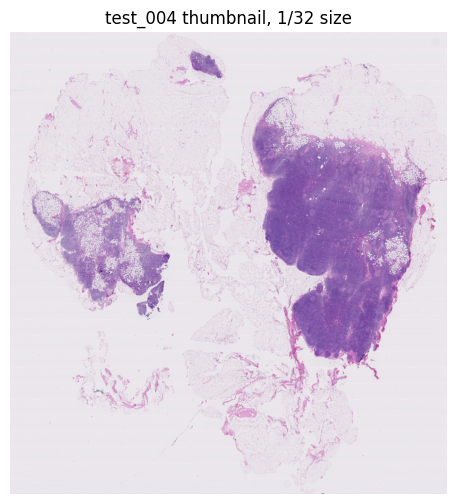

In [9]:
first = download_slide(slides[0])
reader = SlideReader(first)
print(slides[0], f'{reader.width:,} x {reader.height:,} px, {reader.mpp0:.3f} um/px at level 0')
print('levels (downsample):', reader.downsamples)
print(f'as raw RGB this would need {reader.width * reader.height * 3 / 1e9:.0f} GB of RAM')
thumb = reader.thumbnail(THUMB_DS)
plt.figure(figsize = (8, 6))
plt.imshow(thumb)
plt.title(f'{slides[0]} thumbnail, 1/{THUMB_DS} size')
plt.axis('off')
plt.show()

## 4. Tissue mask: skip the glass

Most of a slide is empty glass. Glass is bright and **grey** (low colour saturation); stained tissue is pink/purple (high saturation). So:
1. convert the thumbnail to HSV and take the saturation channel
2. **Otsu's method** picks the threshold that best splits the histogram into two groups (glass vs tissue). It is floored at 0.07, because on an almost empty slide Otsu can pick nonsense
3. clean up: close small gaps, remove specks, fill small holes

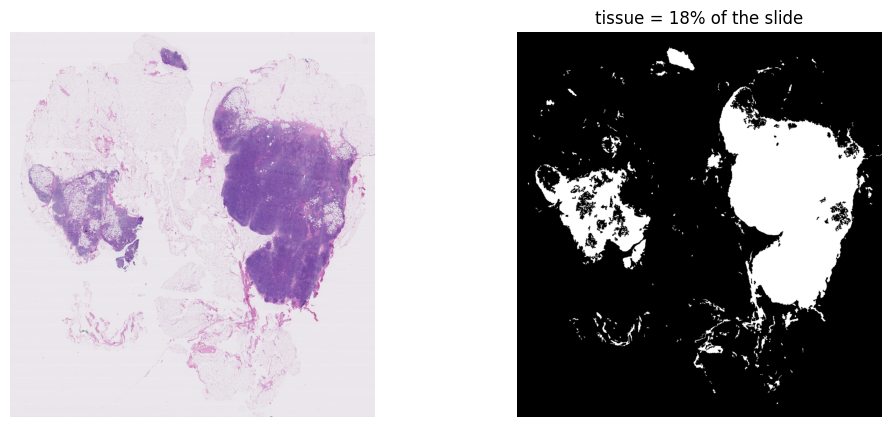

In [10]:
def remove_small(mask, px):
    # scikit-image renamed this argument in 0.26; support both versions
    try:
        return morphology.remove_small_objects(mask, max_size = px)
    except TypeError:
        return morphology.remove_small_objects(mask, min_size = px + 1)


def fill_holes(mask, px):
    try:
        return morphology.remove_small_holes(mask, max_size = px)
    except TypeError:
        return morphology.remove_small_holes(mask, area_threshold = px + 1)


def tissue_mask(rgb):
    hsv = rgb2hsv(rgb)
    sat, val = hsv[..., 1], hsv[..., 2]
    t = max(threshold_otsu(sat), 0.07)
    mask = (sat > t) & (val > 0.1)                      # val > 0.1 drops black scanner borders
    mask = ndi.binary_closing(mask, structure = np.ones((3, 3)), iterations = 2)
    return fill_holes(remove_small(mask, 64), 256)


mask = tissue_mask(thumb)
fig, axes = plt.subplots(1, 2, figsize = (12, 5))
axes[0].imshow(thumb)
axes[1].imshow(mask, cmap = 'gray')
axes[1].set_title(f'tissue = {mask.mean():.0%} of the slide')
for ax in axes:
    ax.axis('off')
plt.show()

## 5. The grid: cells, windows and blocks

All sizes are in pixels at 10× (level 2):
- **cell** = 32 × 32 px (≈ 31 µm), one pixel of the heatmap. It gets exactly one prediction.
- **window** = the 96 × 96 px model input centred on a cell (32 px of context on each side), just like a PCam patch.
- **block** = 32 × 32 cells read from the slide **in one call** (32·32 + 64 = 1,088 px square). The 1,024 windows are then cut out of the block in memory with `tensor.unfold`.

Why blocks: neighbouring windows overlap a lot (each pixel is in 9 windows). Reading every window separately would decode the same JPEG tiles over and over, about 1,000 small reads per block. One big read decodes each tile once.

**Tissue fraction per cell, with an integral image.** For each of ~1 million cells we need "what fraction of this square is tissue?" The integral image `ii[y, x]` = sum of the mask above and left of (y, x). The sum of *any* rectangle is then 4 lookups:

`sum = ii[y1, x1] - ii[y0, x1] - ii[y1, x0] + ii[y0, x0]`

So we build it once (O(H·W)) and answer every cell in O(1). This is 2-D prefix sums, a classic DSA question.

In [11]:
MARGIN = (TILE - STRIDE) // 2                          # 32
BLOCK_PX = CELLS_PER_BLOCK * STRIDE + 2 * MARGIN       # 1088
CELL0 = STRIDE * DOWNSAMPLE                            # cell size in level-0 pixels (128)


def grid_shape(reader):
    return int(reader.height / DOWNSAMPLE) // STRIDE, int(reader.width / DOWNSAMPLE) // STRIDE


def integral_image(mask):
    ii = np.zeros((mask.shape[0] + 1, mask.shape[1] + 1), np.int64)
    ii[1:, 1:] = mask.astype(np.int64).cumsum(0).cumsum(1)
    return ii


def cell_tissue_fraction(mask, n_rows, n_cols):
    ii = integral_image(mask)
    H, W = mask.shape
    s = CELL0 / THUMB_DS                                # cell size in thumbnail pixels (4)
    y0 = np.clip(np.floor(np.arange(n_rows) * s).astype(int), 0, H)
    y1 = np.clip(np.maximum(np.ceil((np.arange(n_rows) + 1) * s).astype(int), y0 + 1), 0, H)
    x0 = np.clip(np.floor(np.arange(n_cols) * s).astype(int), 0, W)
    x1 = np.clip(np.maximum(np.ceil((np.arange(n_cols) + 1) * s).astype(int), x0 + 1), 0, W)
    Y0, X0 = np.meshgrid(y0, x0, indexing = 'ij')
    Y1, X1 = np.meshgrid(y1, x1, indexing = 'ij')
    box_sum = ii[Y1, X1] - ii[Y0, X1] - ii[Y1, X0] + ii[Y0, X0]
    return (box_sum / np.maximum((Y1 - Y0) * (X1 - X0), 1)).astype(np.float32)


def block_origin0(r0, c0):
    # level-0 top-left corner of the block whose first cell is (r0, c0), margin included
    return (c0 * STRIDE - MARGIN) * DOWNSAMPLE, (r0 * STRIDE - MARGIN) * DOWNSAMPLE


def blocks_with_tissue(cells):
    k = CELLS_PER_BLOCK
    return [(r0, c0) for r0 in range(0, cells.shape[0], k) for c0 in range(0, cells.shape[1], k)
            if cells[r0:r0 + k, c0:c0 + k].any()]


def block_to_windows(block):
    # (B, 3, P, P) -> (B * k * k, 3, 96, 96). unfold makes views, no extra reads
    B = block.shape[0]
    w = block.unfold(2, TILE, STRIDE).unfold(3, TILE, STRIDE)          # B, 3, k, k, 96, 96
    k = w.shape[2]
    return w.permute(0, 2, 3, 1, 4, 5).reshape(B * k * k, 3, TILE, TILE), k

In [12]:
n_rows, n_cols = grid_shape(reader)
frac = cell_tissue_fraction(mask, n_rows, n_cols)
cells = frac >= MIN_TISSUE
blocks = blocks_with_tissue(cells)
print(f'grid {n_rows} x {n_cols} = {n_rows * n_cols:,} cells, {cells.sum():,} with tissue')
print(f'{len(blocks)} blocks to read (of {math.ceil(n_rows / CELLS_PER_BLOCK) * math.ceil(n_cols / CELLS_PER_BLOCK)})')

# brute-force check of the integral image on a random box
r = np.random.default_rng(0)
ys, xs = sorted(r.integers(0, mask.shape[0], 2)), sorted(r.integers(0, mask.shape[1], 2))
ii = integral_image(mask)
assert ii[ys[1], xs[1]] - ii[ys[0], xs[1]] - ii[ys[1], xs[0]] + ii[ys[0], xs[0]] == mask[ys[0]:ys[1], xs[0]:xs[1]].sum()
print('integral image check OK')

grid 812 x 768 = 623,616 cells, 120,148 with tissue
309 blocks to read (of 624)
integral image check OK


**Sanity check of the geometry.** If the windows cut from a block are not exactly the windows we would read directly, the heatmap would be shifted, and everything after it would be quietly wrong. So we compare.

In [13]:
r0, c0 = blocks[len(blocks) // 2]
x0, y0 = block_origin0(r0, c0)
block = reader.read(int(x0), int(y0), BLOCK_PX, BLOCK_PX, DOWNSAMPLE)
windows, k = block_to_windows(torch.from_numpy(block).permute(2, 0, 1)[None])
for i, j in [(0, 0), (5, 7), (k - 1, k - 1)]:
    wx, wy = block_origin0(r0 + i, c0 + j)                      # window (i, j) read directly
    direct = reader.read(int(wx), int(wy), TILE, TILE, DOWNSAMPLE)
    diff = np.abs(windows[i * k + j].permute(1, 2, 0).numpy().astype(int) - direct.astype(int)).mean()
    assert diff < 1, diff
print('windows from the block == direct reads: OK')

windows from the block == direct reads: OK


## 6. Run the model over one slide

- A `Dataset` that returns one **block** per item. The slide is opened inside each worker process: an OpenSlide handle can't be shared between processes.
- On the GPU: normalize → `unfold` into 1,024 windows → model in fp16 → sigmoid → write into the heatmap.
- Timing is split into **waiting for data** (reading + JPEG decoding) and **model**. That tells you where the bottleneck is, which is a good interview number.

In [14]:
class BlockDataset(Dataset):
    def __init__(self, path, blocks):
        self.path, self.blocks, self.reader = path, blocks, None

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, i):
        if self.reader is None:
            self.reader = SlideReader(self.path)          # one reader per worker
        r0, c0 = self.blocks[i]
        x0, y0 = block_origin0(r0, c0)
        img = self.reader.read(int(x0), int(y0), BLOCK_PX, BLOCK_PX, DOWNSAMPLE)
        return torch.from_numpy(img).permute(2, 0, 1), torch.tensor([r0, c0])


@torch.no_grad()
def heatmap_for_slide(path):
    t_start = time.time()
    rd = SlideReader(path)
    thumb = rd.thumbnail(THUMB_DS)
    msk = tissue_mask(thumb)
    n_rows, n_cols = grid_shape(rd)
    frac = cell_tissue_fraction(msk, n_rows, n_cols)
    cells = frac >= MIN_TISSUE
    blocks = blocks_with_tissue(cells)
    prob = np.full((n_rows, n_cols), np.nan, np.float32)
    dl = DataLoader(BlockDataset(path, blocks), batch_size = BLOCKS_PER_BATCH, num_workers = WORKERS,
                    pin_memory = use_amp)
    k = CELLS_PER_BLOCK
    wait = compute = 0.0
    t = time.time()
    for x, origins in dl:
        t0 = time.time()
        wait += t0 - t
        x = (x.to(device).float() - MEAN) / STD
        windows, _ = block_to_windows(x)
        out = []
        for i in range(0, len(windows), CHUNK):
            with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
                out.append(torch.sigmoid(model(windows[i:i + CHUNK].contiguous(memory_format = torch.channels_last))).float())
        p = torch.cat(out).view(len(origins), k, k).cpu().numpy()
        compute += time.time() - t0
        for b, (r0, c0) in enumerate(origins.tolist()):
            r1, c1 = min(r0 + k, n_rows), min(c0 + k, n_cols)
            prob[r0:r1, c0:c1] = p[b, :r1 - r0, :c1 - c0]       # edge blocks stick out of the grid
        t = time.time()
    prob[~cells] = np.nan                                       # not tissue
    meta = {'slide': os.path.basename(path)[:-4], 'width': rd.width, 'height': rd.height, 'mpp0': rd.mpp0,
            'cell_um': CELL0 * rd.mpp0, 'tissue_cells': int(cells.sum()), 'windows': len(blocks) * k * k,
            'seconds_total': time.time() - t_start, 'seconds_waiting_for_data': wait, 'seconds_model': compute}
    meta['windows_per_second'] = meta['windows'] / meta['seconds_total']
    return prob, thumb, meta


def overlay(thumb, prob, alpha = 0.55):
    # heatmap (yellow -> red) on top of the thumbnail
    H, W = thumb.shape[:2]
    p = np.nan_to_num(prob, nan = 0.0)
    p = np.asarray(Image.fromarray((p * 255).astype(np.uint8)).resize((W, H), Image.NEAREST)) / 255.0
    color = np.stack([np.ones_like(p), 1 - p, np.zeros_like(p)], -1) * 255
    a = (alpha * p)[..., None]
    return (thumb * (1 - a) + color * a).astype(np.uint8)


def save_heatmap(prob, thumb, meta):
    name = meta['slide']
    np.savez_compressed(f'{HEATMAPS}/{name}.npz', prob = prob.astype(np.float16))
    json.dump(meta, open(f'{HEATMAPS}/{name}.json', 'w'), indent = 2)
    small = Image.fromarray(thumb)
    small.thumbnail((1600, 1600))
    small = np.asarray(small)
    Image.fromarray(overlay(small, prob)).save(f'{HEATMAPS}/{name}_overlay.png')

316,416 windows in 31 s (10047/s); waiting for data 6 s, model 21 s
slide label: tumor | max cell probability 1.0


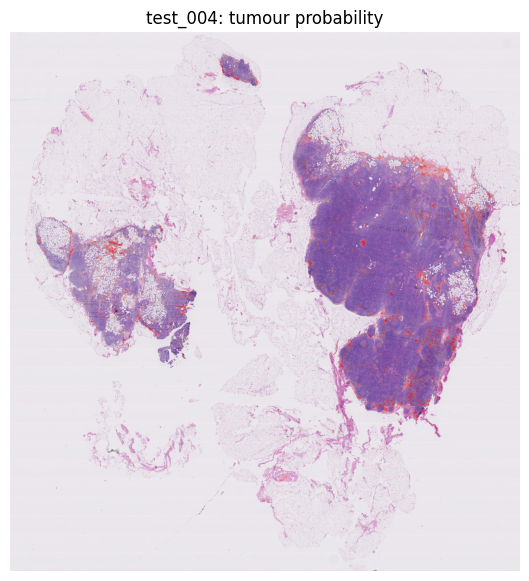

In [15]:
prob, thumb, meta = heatmap_for_slide(first)
save_heatmap(prob, thumb, meta)
print(f"{meta['windows']:,} windows in {meta['seconds_total']:.0f} s ({meta['windows_per_second']:.0f}/s); "
      f"waiting for data {meta['seconds_waiting_for_data']:.0f} s, model {meta['seconds_model']:.0f} s")
print('slide label:', ref.loc[meta['slide'], 'type'], '| max cell probability', round(float(np.nanmax(prob)), 3))
plt.figure(figsize = (9, 7))
plt.imshow(overlay(thumb, prob))
plt.title(f"{meta['slide']}: tumour probability")
plt.axis('off')
plt.show()

**Check:** the red should sit on tissue, never on the glass. On a tumour slide it should roughly match the annotated region (section 9 measures this).

## 7. All slides: download → heatmap → delete

A slide is 1-2.3 GB and 40 of them don't fit on the disk, so each one is downloaded, processed and deleted. The heatmap (a few MB) goes to Drive straight away. **Safe to rerun after a disconnect:** finished slides are skipped.

In [16]:
os.remove(first)
for i, name in enumerate(slides, 1):
    if os.path.exists(f'{HEATMAPS}/{name}.npz'):
        print(f'[{i}/{len(slides)}] {name} done already')
        continue
    path = download_slide(name)
    prob, thumb, meta = heatmap_for_slide(path)
    save_heatmap(prob, thumb, meta)
    os.remove(path)
    print(f"[{i}/{len(slides)}] {name} ({ref.loc[name, 'type']}): {meta['windows']:,} windows in "
          f"{meta['seconds_total']:.0f} s, max prob {np.nanmax(prob):.3f}")

[1/40] test_004 done already
[2/40] test_006 (normal): 327,680 windows in 39 s, max prob 1.000
[3/40] test_007 (normal): 197,632 windows in 28 s, max prob 0.999
[4/40] test_010 (tumor): 327,680 windows in 37 s, max prob 1.000
[5/40] test_015 (normal): 75,776 windows in 19 s, max prob 0.996
[6/40] test_016 (tumor): 373,760 windows in 36 s, max prob 1.000
[7/40] test_027 (tumor): 198,656 windows in 29 s, max prob 1.000
[8/40] test_029 (tumor): 128,000 windows in 24 s, max prob 1.000
[9/40] test_037 (normal): 459,776 windows in 45 s, max prob 0.999
[10/40] test_040 (tumor): 112,640 windows in 22 s, max prob 1.000
[11/40] test_043 (normal): 109,568 windows in 22 s, max prob 0.999
[12/40] test_044 (normal): 193,536 windows in 19 s, max prob 1.000
[13/40] test_050 (normal): 324,608 windows in 39 s, max prob 1.000
[14/40] test_051 (tumor): 150,528 windows in 23 s, max prob 1.000
[15/40] test_056 (normal): 438,272 windows in 48 s, max prob 0.999
[16/40] test_063 (normal): 312,320 windows in 28

## 8. Slide-level results

From a heatmap to one number per slide. The **primary score** is fixed before looking at any results: the **maximum of the 3 × 3-smoothed heatmap**. A single bright cell is often noise; a bright 3 × 3 neighbourhood rarely is. The other scores are shown for comparison only. Picking whichever looks best on test would be tuning on test.

**Connected components (BFS).** Cells above 0.5 that touch (8 neighbours) form one tumour region. Finding them is the "number of islands" problem: a breadth-first search from each unvisited cell.

In [17]:
def connected_components(binary):
    # bfs flood fill, 8-connected. returns label image and number of regions
    H, W = binary.shape
    labels = np.zeros((H, W), np.int32)
    n = 0
    for sy, sx in zip(*np.nonzero(binary)):
        if labels[sy, sx]:
            continue
        n += 1
        labels[sy, sx] = n
        q = deque([(sy, sx)])
        while q:
            y, x = q.popleft()
            for dy in (-1, 0, 1):
                for dx in (-1, 0, 1):
                    ny, nx = y + dy, x + dx
                    if 0 <= ny < H and 0 <= nx < W and binary[ny, nx] and not labels[ny, nx]:
                        labels[ny, nx] = n
                        q.append((ny, nx))
    return labels, n


# check against scipy on random data
b = np.random.default_rng(1).random((40, 50)) > 0.6
assert connected_components(b)[1] == ndi.label(b, structure = np.ones((3, 3)))[1]
print('bfs == scipy: OK')


def slide_features(prob, cell_mm2):
    tissue = ~np.isnan(prob)
    p = np.nan_to_num(prob, nan = 0.0)
    smooth = ndi.uniform_filter(p, size = 3, mode = 'constant')
    pos = p >= CELL_THRESHOLD
    labels, n = connected_components(pos)
    sizes = np.bincount(labels.ravel())[1:] if n else np.array([0])
    v = p[tissue]
    return {'max_smooth': float(smooth.max()), 'max_prob': float(p.max()),
            'top10_mean': float(np.sort(v)[-10:].mean()) if len(v) else 0.0,
            'tumour_area_mm2': float(pos.sum() * cell_mm2), 'n_regions': n,
            'largest_region_mm2': float(sizes.max() * cell_mm2), 'tissue_area_mm2': float(tissue.sum() * cell_mm2)}

bfs == scipy: OK


In [18]:
rows, heat = [], {}
for f in sorted(glob.glob(f'{HEATMAPS}/*.npz')):
    name = os.path.basename(f)[:-4]
    if not name.startswith('test_'):
        print('skipped (not a test slide):', name)
        continue
    prob = np.load(f)['prob'].astype(np.float32)
    meta = json.load(open(f'{HEATMAPS}/{name}.json'))
    heat[name] = (prob, meta)
    rows.append({'slide': name, 'label': int(ref.loc[name, 'type'] == 'tumor'), 'class': ref.loc[name, 'class'],
                 'center': int(ref.loc[name, 'center']), 'seconds': meta['seconds_total'],
                 'windows_per_s': meta['windows_per_second']} | slide_features(prob, (meta['cell_um'] / 1000) ** 2))
df = pd.DataFrame(rows).set_index('slide')
df.to_csv(f'{EVAL}/per_slide.csv')
print(len(df), 'slides:', df.label.sum(), 'tumour,', (1 - df.label).sum(), 'normal')

40 slides: 20 tumour, 20 normal


In [19]:
def bootstrap_auc(y, s, n_boot = 2000, seed = 0):
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            aucs.append(roc_auc_score(y[i], s[i]))
    return np.percentile(aucs, [2.5, 97.5]).round(3).tolist()


results = {'slides': len(df), 'tumour_slides': int(df.label.sum())}
y = df.label.values
for s in ['max_smooth', 'max_prob', 'top10_mean', 'tumour_area_mm2', 'largest_region_mm2']:
    auc = roc_auc_score(y, df[s])
    results[f'auc_{s}'] = {'auc': round(float(auc), 3), 'ci95': bootstrap_auc(y, df[s].values)}
    print(f'slide AUC {s:20s} {auc:.3f}  95% CI {results[f"auc_{s}"]["ci95"]}' + ('   <- primary' if s == 'max_smooth' else ''))
for c, g in df.groupby('center'):
    if g.label.nunique() == 2:
        results[f'auc_center_{c}'] = round(float(roc_auc_score(g.label, g.max_smooth)), 3)
        print(f'  hospital {c}: {len(g)} slides, AUC {results[f"auc_center_{c}"]}')
flag = df.max_smooth >= 0.5
results['recall_at_0.5'] = round(float(flag[df.label == 1].mean()), 3)
results['specificity_at_0.5'] = round(float((~flag)[df.label == 0].mean()), 3)
results['recall_by_class'] = flag[df.label == 1].groupby(df['class']).mean().round(3).to_dict()
results['median_windows_per_s'] = round(float(df.windows_per_s.median()))
print({k: results[k] for k in ['recall_at_0.5', 'specificity_at_0.5', 'recall_by_class', 'median_windows_per_s']})

slide AUC max_smooth           0.945  95% CI [0.853, 1.0]   <- primary
slide AUC max_prob             0.819  95% CI [0.698, 0.927]
slide AUC top10_mean           0.921  95% CI [0.826, 0.992]
slide AUC tumour_area_mm2      0.823  95% CI [0.685, 0.938]
slide AUC largest_region_mm2   0.917  95% CI [0.821, 0.982]
  hospital 0: 24 slides, AUC 1.0
  hospital 1: 16 slides, AUC 0.817
{'recall_at_0.5': 1.0, 'specificity_at_0.5': 0.0, 'recall_by_class': {'macro': 1.0, 'micro': 1.0}, 'median_windows_per_s': 8500}


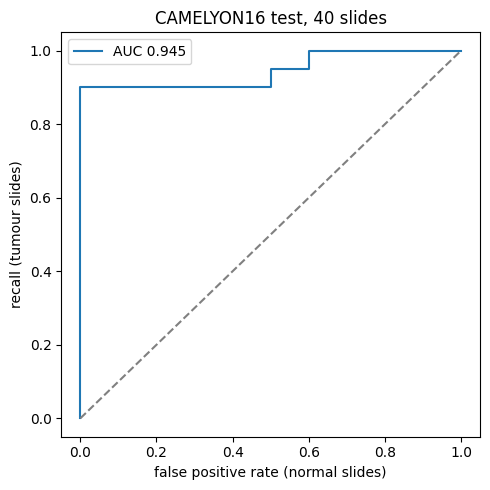

,label,class,center,max_smooth,tumour_area_mm2,n_regions
slide,,,,,,
test_111,0,negative,0,0.700,0.381,171
test_015,0,negative,0,0.822,0.445,150
test_087,0,negative,0,0.888,0.325,186
test_056,0,negative,0,0.913,3.602,1252
test_123,0,negative,0,0.927,0.401,170
test_106,0,negative,0,0.928,0.565,259
test_043,0,negative,0,0.954,0.455,178
test_006,0,negative,0,0.963,2.426,765
test_099,1,micro,1,0.967,1.031,310


In [20]:
fpr, tpr, _ = roc_curve(y, df.max_smooth)
plt.figure(figsize = (5, 5))
plt.plot(fpr, tpr, label = f"AUC {results['auc_max_smooth']['auc']}")
plt.plot([0, 1], [0, 1], '--', color = 'grey')
plt.xlabel('false positive rate (normal slides)')
plt.ylabel('recall (tumour slides)')
plt.title(f'CAMELYON16 test, {len(df)} slides')
plt.legend()
plt.tight_layout()
plt.savefig(f'{EVAL}/camelyon_slide_roc.png', dpi = 120)
plt.show()
# hardest cases: lowest-scoring tumour slides and highest-scoring normal slides
df.sort_values('max_smooth')[['label', 'class', 'center', 'max_smooth', 'tumour_area_mm2', 'n_regions']].round(3)

## 9. Lesion-level results (using the pathologists' outlines)

1. Turn each XML outline into a mask on our heatmap grid (a cell counts as tumour if its centre is inside the outline, and not inside an "Exclusion" area).
2. **Cell-level AUC and Dice** on tumour slides: how well the heatmap outlines the tumour.
3. **Lesion detection:** every separate annotated tumour region is a lesion. A lesion is **found** if any predicted tumour cell touches it. A **false-positive region** is a predicted region that touches no lesion. Like the CAMELYON16 challenge, lesions smaller than 200 µm (isolated tumour cells) are not counted.

This is a simpler cousin of the challenge's FROC metric (which sweeps the threshold), at one threshold (0.5).

In [21]:
def lesion_mask(xml_path, n_rows, n_cols):
    tumour = np.zeros((n_rows, n_cols), bool)
    excl = np.zeros((n_rows, n_cols), bool)
    if not os.path.exists(xml_path):
        return tumour                                    # normal slides have no xml
    for ann in ET.parse(xml_path).getroot().iter('Annotation'):
        pts = np.array([(float(c.get('X')), float(c.get('Y'))) for c in ann.iter('Coordinate')])
        if len(pts) < 3:
            continue
        rr, cc = draw_polygon(pts[:, 1] / CELL0 - 0.5, pts[:, 0] / CELL0 - 0.5, shape = (n_rows, n_cols))
        is_excl = ann.get('PartOfGroup') in ('Exclusion', '_2')
        if len(rr) == 0 and not is_excl:                 # lesion smaller than one cell: keep its centre cell
            rr = np.array([min(int(pts[:, 1].mean() / CELL0), n_rows - 1)])
            cc = np.array([min(int(pts[:, 0].mean() / CELL0), n_cols - 1)])
        (excl if is_excl else tumour)[rr, cc] = True
    return tumour & ~excl


ys, ps = [], []
found = lesions = fp_regions = 0
for name, (prob, meta) in heat.items():
    gt = lesion_mask(f'{CAM}/annotations/{name}.xml', *prob.shape)
    tissue = ~np.isnan(prob)
    pred = (np.nan_to_num(prob) >= CELL_THRESHOLD) & tissue
    if gt.any():
        ys.append(gt[tissue])
        ps.append(prob[tissue])
    gt_lab, n_gt = connected_components(gt)
    for k, sl in enumerate(ndi.find_objects(gt_lab), start = 1):
        if max(sl[0].stop - sl[0].start, sl[1].stop - sl[1].start) * meta['cell_um'] < 200:
            continue                                      # isolated tumour cells: not scored
        lesions += 1
        found += bool((pred & ndi.binary_dilation(gt_lab == k)).any())
    near = ndi.binary_dilation(gt) if n_gt else gt
    pr_lab, n_pr = connected_components(pred)
    fp_regions += sum(1 for k in range(1, n_pr + 1) if not (near & (pr_lab == k)).any())

ys, ps = np.concatenate(ys), np.concatenate(ps)
results['cell_auc_tumour_slides'] = round(float(roc_auc_score(ys, ps)), 3)
pr = ps >= CELL_THRESHOLD
results['cell_dice_tumour_slides'] = round(float(2 * (pr & ys).sum() / (pr.sum() + ys.sum())), 3)
results['lesions_found'] = f'{found} / {lesions}'
results['fp_regions_per_slide'] = round(fp_regions / len(heat), 2)
print({k: results[k] for k in ['cell_auc_tumour_slides', 'cell_dice_tumour_slides', 'lesions_found', 'fp_regions_per_slide']})
json.dump(results, open(f'{EVAL}/camelyon_results.json', 'w'), indent = 2, default = str)

{'cell_auc_tumour_slides': 0.986, 'cell_dice_tumour_slides': 0.904, 'lesions_found': '139 / 140', 'fp_regions_per_slide': 609.95}


**Files for the Streamlit app:** heatmaps of the 2 highest-scoring tumour slides and the 2 lowest-scoring normal slides.

In [22]:
APP = f'{OUT}/app_artifacts/heatmaps'
os.makedirs(APP, exist_ok = True)
keep = df[df.label == 1].max_smooth.nlargest(2).index.tolist() + df[df.label == 0].max_smooth.nsmallest(2).index.tolist()
for name in keep:
    for ext in ['.npz', '.json', '_overlay.png']:
        shutil.copy(f'{HEATMAPS}/{name}{ext}', APP)
print(keep)

['test_016', 'test_027', 'test_111', 'test_015']


## 10. Summary: write these into RESULTS.md

| What | Where |
|---|---|
| slide AUC (primary = `max_smooth`) + 95% CI | section 8 |
| AUC per hospital | section 8 |
| recall at 0.5 for macro vs micro metastases | section 8 |
| windows per second; waiting for data vs model time | sections 6 and 8 |
| cell-level AUC / Dice, lesions found, FP regions per slide | section 9 |
| 2-3 overlays (one tumour, one normal) for `assets/` | `MyDrive/patho/heatmaps/*_overlay.png` |

What to expect and how to explain it: the CAMELYON16 winners used 40× patches and a second-stage model. A 10× PCam model scores lower, and its misses are mostly **micro**-metastases (a few cells are only a few pixels at 10×). With 40 slides the CI is wide; say so.